<a href="https://colab.research.google.com/github/Komal5578/DWM/blob/main/kmeans_my_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-MEANS CLUSTERING (paper-ready)
**Edit only the ✏️ DATA cell** (points + starting centroids/seeds). Part A shows every iteration like a hand calculation; Part B uses the library (`sklearn`) and the elbow method.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.width', 200)

## ✏️ DATA: points and starting centroids from the question

In [2]:
points = {                      # name: (x, y)  (works with 3+ numbers per point too)
 'P1':(2,4), 'P2':(2,6), 'P3':(5,6), 'P4':(4,7), 'P5':(8,3),
 'P6':(6,6), 'P7':(5,2), 'P8':(5,7), 'P9':(6,3), 'P10':(4,4),
}
seeds = [(1,5), (4,1), (8,4)]   # initial centroids given in the question  (k = number of seeds)

# No seeds given? Use the first k points instead:  K = 3; seeds = list(points.values())[:K]

## PART A: K-means step by step (no library)
Each round: ① distance of every point to every centroid ② assign to the nearest ③ new centroid = mean of its cluster ④ stop when nothing changes.

In [3]:
names = list(points)
X = np.array([points[n] for n in names], dtype=float)
C = np.array(seeds, dtype=float)
k = len(C)
old_labels = None

for it in range(1, 50):
    # ① Euclidean distance point -> each centroid
    D = np.sqrt(((X[:, None, :] - C[None, :, :])**2).sum(axis=2))
    table = pd.DataFrame(D.round(2), index=names, columns=[f'd(C{j+1})' for j in range(k)])
    # ② assign
    labels = D.argmin(axis=1)
    table['Cluster'] = ['C'+str(l+1) for l in labels]
    print(f'===== Iteration {it} =====')
    print('Centroids used:', {f'C{j+1}': tuple(float(x) for x in C[j].round(2)) for j in range(k)})
    print(table, '\n')
    # stop if assignments unchanged
    if old_labels is not None and (labels == old_labels).all():
        print('Assignments did not change -> CONVERGED'); break
    old_labels = labels.copy()
    # ③ new centroids
    for j in range(k):
        if (labels == j).any():
            C[j] = X[labels == j].mean(axis=0)
    print('New centroids:', {f'C{j+1}': tuple(float(x) for x in C[j].round(2)) for j in range(k)}, '\n')

print('\nFINAL CLUSTERS')
for j in range(k):
    print(f'C{j+1} centroid {tuple(float(x) for x in C[j].round(2))}:', [n for n, l in zip(names, labels) if l == j])

===== Iteration 1 =====
Centroids used: {'C1': (1.0, 5.0), 'C2': (4.0, 1.0), 'C3': (8.0, 4.0)}
     d(C1)  d(C2)  d(C3) Cluster
P1    1.41   3.61   6.00      C1
P2    1.41   5.39   6.32      C1
P3    4.12   5.10   3.61      C3
P4    3.61   6.00   5.00      C1
P5    7.28   4.47   1.00      C3
P6    5.10   5.39   2.83      C3
P7    5.00   1.41   3.61      C2
P8    4.47   6.08   4.24      C3
P9    5.39   2.83   2.24      C3
P10   3.16   3.00   4.00      C2 

New centroids: {'C1': (2.67, 5.67), 'C2': (4.5, 3.0), 'C3': (6.0, 5.0)} 

===== Iteration 2 =====
Centroids used: {'C1': (2.67, 5.67), 'C2': (4.5, 3.0), 'C3': (6.0, 5.0)}
     d(C1)  d(C2)  d(C3) Cluster
P1    1.80   2.69   4.12      C1
P2    0.75   3.91   4.12      C1
P3    2.36   3.04   1.41      C3
P4    1.89   4.03   2.83      C1
P5    5.96   3.50   2.83      C3
P6    3.35   3.35   1.00      C3
P7    4.35   1.12   3.16      C2
P8    2.69   4.03   2.24      C3
P9    4.27   1.50   2.00      C2
P10   2.13   1.12   2.24      C2 

New 

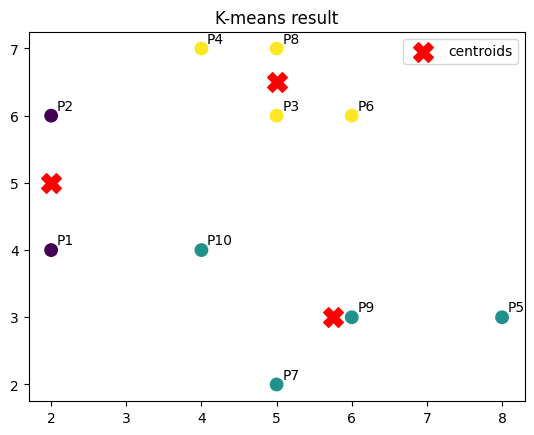

In [4]:
if X.shape[1] == 2:
    plt.scatter(X[:,0], X[:,1], c=labels, cmap='viridis', s=80)
    for n, (x, y) in zip(names, X): plt.annotate(n, (x, y), xytext=(4,4), textcoords='offset points')
    plt.scatter(C[:,0], C[:,1], c='red', marker='X', s=200, label='centroids'); plt.legend()
    plt.title('K-means result'); plt.show()

## PART B: with the library (`sklearn`)

In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# same starting seeds -> same answer as Part A
km = KMeans(n_clusters=k, init=np.array(seeds, dtype=float), n_init=1).fit(X)
print('Labels   :', {n: int(l) + 1 for n, l in zip(names, km.labels_)})
print('Centroids:\n', km.cluster_centers_.round(2))
print('Inertia (sum of squared distances):', round(km.inertia_, 2))
print('Silhouette:', round(silhouette_score(X, km.labels_), 3))

Labels   : {'P1': 1, 'P2': 1, 'P3': 3, 'P4': 3, 'P5': 2, 'P6': 3, 'P7': 2, 'P8': 3, 'P9': 2, 'P10': 2}
Centroids:
 [[2.   5.  ]
 [5.75 3.  ]
 [5.   6.5 ]]
Inertia (sum of squared distances): 15.75
Silhouette: 0.434


### Elbow method (choose k)
Pick the k where the curve bends ("elbow").

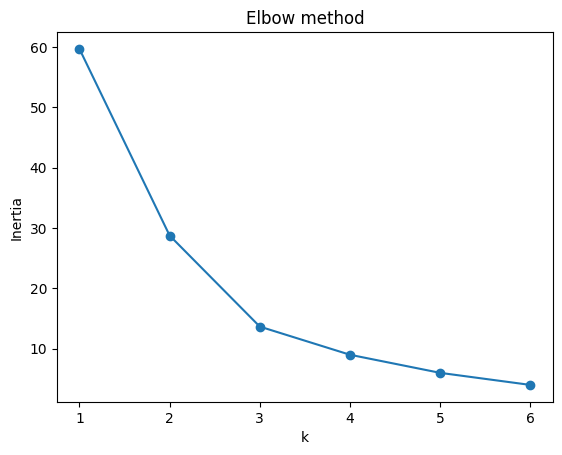

In [6]:
ks = range(1, min(7, len(X)))
inertia = [KMeans(n_clusters=i, n_init=10, random_state=0).fit(X).inertia_ for i in ks]
plt.plot(list(ks), inertia, marker='o'); plt.xlabel('k'); plt.ylabel('Inertia'); plt.title('Elbow method'); plt.show()

### If the paper gives a table (DataFrame) with many columns
```python
df = pd.DataFrame(data, columns=[...])
X = StandardScaler().fit_transform(df[['col1','col2']])   # scale first (distance-based!)
labels = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(X)
```
**Viva:** K-means is unsupervised; needs k in advance; sensitive to seeds/outliers; centroid = mean of cluster; scale features first.